# Step 1 - Cleaning the PubMed-Diabetes data

Goal: turn the two raw files into a clean directed citation graph (`data/processed/`).
All the logic is in `src/data.py`; this notebook only runs it and shows what happened.

**On Colab** run the first cell once; locally you can skip it.

In [1]:
# Colab only: get the repo and install what is missing
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('Final-Project'):
    !git clone https://github.com/ShaharBar99/Final-Project.git
    %cd Final-Project
    !pip install -q -r requirements.txt
else:
    # when running locally from the notebooks folder, move to the project root
    if os.path.basename(os.getcwd()) == 'notebooks':
        os.chdir('..')
sys.path.insert(0, os.getcwd())

## 1. Run the cleaning pipeline

In [2]:
from src import data

nodes, edges, log = data.clean_dataset()
for entry in log:
    print(entry)

{'step': 'load_raw', 'nodes': 19717, 'edges': 44338, 'label_counts': {1: 4103, 2: 7875, 3: 7739}}
{'step': 'remove_duplicate_edges', 'removed': 0, 'edges_left': 44338}
{'step': 'remove_self_loops', 'removed': 3, 'edges_left': 44335, 'examples': ['10751750', '9221759', '1586783']}
{'step': 'resolve_mutual_citations', 'removed': 11, 'edges_left': 44324, 'examples': ['7860729->7860730', '19956098->19956106', '11032783->11032784', '9042931->9042932', '19956107->19956108']}
{'step': 'drop_edges_with_unknown_papers', 'removed': 0, 'edges_left': 44324}
{'step': 'remove_isolated_nodes', 'removed': 0, 'nodes_left': 19717}
{'step': 'final_checks', 'nodes': 19717, 'edges': 44324, 'weakly_connected_components': 1, 'directed_cycles_groups': 0}


## 2. What we removed

The numbers above as a small table (edges only):

In [3]:
import pandas as pd
steps = pd.DataFrame([e for e in log if 'removed' in e])[['step', 'removed']]
steps

,step,removed
0,remove_duplicate_edges,0
1,remove_self_loops,3
2,resolve_mutual_citations,11
3,drop_edges_with_unknown_papers,0
4,remove_isolated_nodes,0


## 3. Quick look at the cleaned graph

In [4]:
g = data.check_graph(edges, [])
indeg = pd.Series(dict(g.in_degree()))
outdeg = pd.Series(dict(g.out_degree()))
print('nodes:', g.number_of_nodes(), ' edges:', g.number_of_edges())
print('density:', round(g.number_of_edges() / (g.number_of_nodes() * (g.number_of_nodes() - 1)), 7))
print('max in-degree:', indeg.max(), ' max out-degree:', outdeg.max())
print('papers never cited:', (indeg == 0).sum(), ' papers that cite nothing:', (outdeg == 0).sum())

nodes: 19717  edges: 44324
density: 0.000114
max in-degree: 171  max out-degree: 130
papers never cited: 2047  papers that cite nothing: 15840


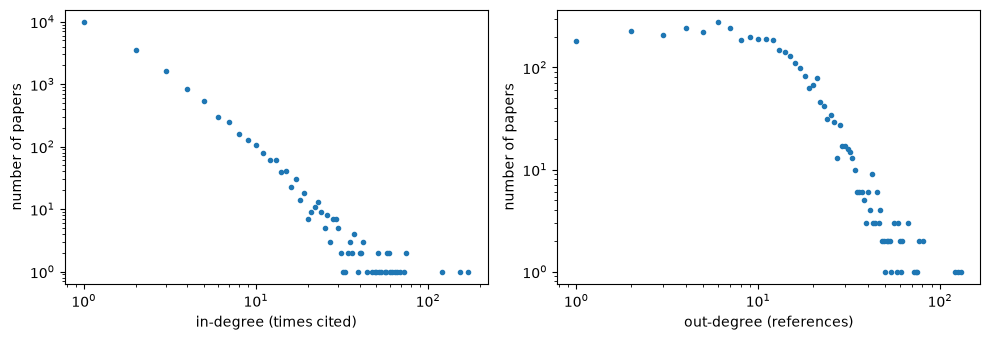

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, s, name in zip(ax, [indeg, outdeg], ['in-degree (times cited)', 'out-degree (references)']):
    counts = s.value_counts().sort_index()
    a.loglog(counts.index[counts.index > 0], counts[counts.index > 0], '.')
    a.set_xlabel(name); a.set_ylabel('number of papers')
plt.tight_layout(); plt.show()

## 4. Save

Writes `nodes.csv`, `edges.csv` and `cleaning_log.json` to `data/processed/`.

In [6]:
data.save_dataset(nodes, edges, log)
print('saved')

saved
